# 26 - A Multi-Agent Research Assistant, with a Verifier that Checks the Claims
**Topic:** AI Agents  |  **Reference:** "Building a Multi-Agent System using Gemini API" (amanxai.com, Sep 2025)

**Question.** If several specialised agents (a planner, a researcher, a writer) cooperate to produce a short report on a topic, how do we know the report is *supported by its sources*?

**Reference method:** three Gemini-powered agents in sequence: **Planner** (splits a topic into sub-topics), **Researcher** (writes about each), **Synthesizer** (merges into a report). The agents' output is judged by reading it.
**What I do:** build the same pipeline but with **grounding**: the researcher retrieves passages from real Wikipedia articles and the writer must cite them; I add a fourth agent, the **Verifier**, that checks each sentence against its cited evidence with a language-inference model. Then I **measure**: (1) can the verifier catch planted errors (changed numbers, negations, swapped names, off-topic sentences)? (2) how often does an *abstractive* writer produce sentences the evidence does not support, as judged by a second, independent model? (3) does the verifier-guarded pipeline reduce that rate, and at what cost?
**LLM back-end.** The agents run without any paid API: the planner uses fixed question templates, the researcher uses sentence-embedding retrieval, the writers are an extractive picker and **DistilBART** (a small summarisation model). A `ClaudeAgent` class in section 9 shows where an LLM would replace the planner and writer, but **it was not run** (no API key was available in this session).

## 1. Libraries and the knowledge base (Wikipedia)

In [1]:
import warnings, os, re, json, joblib, time, random, urllib.request, urllib.parse, urllib.error, collections
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch
sns.set_theme(style="whitegrid", context="notebook")
torch.set_num_threads(6); random.seed(0); np.random.seed(0); os.makedirs("model", exist_ok=True); os.makedirs("../_data/wikipedia", exist_ok=True)
TOPICS = ["Photosynthesis", "Blockchain", "Climate change", "Machine learning", "Vaccine", "Solar power", "Black hole", "Antibiotic", "Electric vehicle", "Great Wall of China", "French Revolution", "Coffee"]
def fetch(title):
    f = "../_data/wikipedia/" + title.replace(" ", "_") + ".txt"
    if os.path.exists(f): return open(f, encoding="utf8").read()
    url = "https://en.wikipedia.org/w/api.php?" + urllib.parse.urlencode({"action": "query", "prop": "extracts", "explaintext": 1, "titles": title, "format": "json", "redirects": 1})
    for k in range(7):                                       # Wikipedia rate-limits fast clients (HTTP 429): wait and retry
        try:
            txt = list(json.load(urllib.request.urlopen(urllib.request.Request(url, headers={"User-Agent": "learning-notebook/1.0 (educational project)"}), timeout=30))["query"]["pages"].values())[0]["extract"]; break
        except urllib.error.HTTPError as e:
            if e.code != 429 or k == 6: raise
            time.sleep(8 * 2 ** k)
    time.sleep(2)
    open(f, "w", encoding="utf8").write(txt); return txt
DROP = {"see also", "references", "external links", "further reading", "notes", "bibliography", "sources", "citations", "footnotes", "gallery"}
def passages(title, text, target=90):
    out, sec, buf = [], "Introduction", []
    def flush():
        nonlocal buf
        if buf and sec.lower() not in DROP:
            t = " ".join(buf).strip()
            if len(t.split()) >= 25: out.append({"topic": title, "section": sec, "text": t})
        buf = []
    for line in text.split("\n"):
        m = re.match(r"^=+\s*(.*?)\s*=+$", line.strip())
        if m: flush(); sec = m.group(1); continue
        if not line.strip(): continue
        buf.append(line.strip())
        if len(" ".join(buf).split()) >= target: flush()
    flush(); return out
P = pd.DataFrame([p for t in TOPICS for p in passages(t, fetch(t))]); P["pid"] = np.arange(len(P)); P["words"] = P.text.str.split().str.len()
print(len(P), "passages from", P.topic.nunique(), "articles |", int(P.words.sum()), "words | passage length: median", int(P.words.median()))
print(P.groupby("topic").agg(passages=("pid", "size"), words=("words", "sum")).T.to_string())

807 passages from 12 articles | 93144 words | passage length: median 110
topic     Antibiotic  Black hole  Blockchain  Climate change  Coffee  Electric vehicle  French Revolution  Great Wall of China  Machine learning  Photosynthesis  Solar power  Vaccine
passages          58          93          59              78      73                74                102                   29                74              53           41       73
words           6781       10894        6188            9550    8592              7413              12811                 3748              8110            7134         4464     7459


## 2. The four agents
* **Planner:** turns a topic into five sub-questions (definition, history, how it works, uses, risks and limits).
* **Researcher:** retrieves the 3 most relevant passages of *that topic's article* for each question with sentence embeddings (MiniLM) and picks the 4 evidence sentences most similar to the question.
* **Writer** (two versions): *extractive* (the top 2 evidence sentences, verbatim) or *abstractive* (DistilBART rewrites the 4 evidence sentences in about 50 words). Each sentence carries the ids of the passages used.
* **Verifier:** for each written sentence, a natural-language-inference model (MiniLM cross-encoder) estimates the probability that the *evidence entails* the sentence.

In [2]:
from sentence_transformers import SentenceTransformer, CrossEncoder
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForSequenceClassification
emb = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2"); PE = emb.encode(list(P.text), normalize_embeddings=True, batch_size=64)
SPLIT = re.compile(r'(?<=[.!?])\s+(?=[A-Z0-9"])')
def sents(t): return [s.strip() for s in SPLIT.split(t) if len(s.split()) >= 5]
ASPECTS = ["What is {t} and how is it defined?", "What is the history of {t}?", "How does {t} work?", "What are the main uses and applications of {t}?", "What are the risks, criticisms or limitations of {t}?"]
class Planner:
    def plan(self, topic): return [a.format(t=topic) for a in ASPECTS]
class Researcher:
    def __init__(self, P, PE): self.P, self.PE = P, PE
    def research(self, topic, question, k=3, n_sent=4):
        idx = np.where(self.P.topic.values == topic)[0]; q = emb.encode([question], normalize_embeddings=True)[0]; top = idx[np.argsort(-(self.PE[idx] @ q))[:k]]
        cand = [(s, int(pid)) for pid in top for s in sents(self.P.text[pid])]; se = emb.encode([c[0] for c in cand], normalize_embeddings=True); sc = se @ q
        order = np.argsort(-sc)[:n_sent]; return {"question": question, "evidence": [cand[i] for i in order], "scores": [float(sc[i]) for i in order]}
tk = AutoTokenizer.from_pretrained("sshleifer/distilbart-cnn-6-6"); bart = AutoModelForSeq2SeqLM.from_pretrained("sshleifer/distilbart-cnn-6-6").eval()
class Writer:
    def __init__(self, mode): self.mode = mode; self.memo = {}
    def write(self, finding):
        ev = finding["evidence"]; pids = sorted({p for _, p in ev})
        if self.mode == "extractive": return [(s, [p]) for s, p in ev[:2]]
        key = " ".join(s for s, _ in ev)
        if key in self.memo: return self.memo[key]
        b = tk(" ".join(s for s, _ in ev), truncation=True, max_length=400, return_tensors="pt")
        with torch.no_grad(): g = bart.generate(**b, num_beams=4, max_length=70, min_length=25, no_repeat_ngram_size=3, early_stopping=True)
        out = tk.decode(g[0], skip_special_tokens=True).strip(); self.memo[key] = [(s.strip(), pids) for s in SPLIT.split(out) if len(s.split()) >= 4]; return self.memo[key]
nli = AutoModelForSequenceClassification.from_pretrained("cross-encoder/nli-MiniLM2-L6-H768").eval(); nli_tok = AutoTokenizer.from_pretrained("cross-encoder/nli-MiniLM2-L6-H768")
judge = AutoModelForSequenceClassification.from_pretrained("MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli").eval(); judge_tok = AutoTokenizer.from_pretrained("MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli")
def entail(model, tok, premise, hyp):
    b = tok(premise, hyp, truncation=True, max_length=512, return_tensors="pt")
    with torch.no_grad(): p = torch.softmax(model(**b).logits, -1)[0]
    ie = [i for i, l in model.config.id2label.items() if l.lower().startswith("entail")][0]; return float(p[ie])
class Verifier:
    def __init__(self, thr=0.5): self.thr = thr
    def check(self, sentence, premise): p = entail(nli, nli_tok, premise, sentence); return p, p >= self.thr
print("labels of the verifier:", nli.config.id2label, "| labels of the judge:", judge.config.id2label)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


Loading weights:   0%|          | 0/262 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

labels of the verifier: {0: 'contradiction', 1: 'entailment', 2: 'neutral'} | labels of the judge: {0: 'entailment', 1: 'neutral', 2: 'contradiction'}


## 3. A full report for one topic
Planner -> researcher -> writer (abstractive) -> verifier, printed with the verifier's support probability and the passage ids.

In [3]:
planner, researcher, ver = Planner(), Researcher(P, PE), Verifier(0.5)
def build_report(topic, writer, guard=False, fallback=None):
    rep = []
    for q in planner.plan(topic):
        f = researcher.research(topic, q); premise = " ".join(s for s, _ in f["evidence"]); out = []
        for s, pids in writer.write(f):
            p, ok = ver.check(s, premise)
            if guard and not ok and fallback is not None:
                for s2, pids2 in fallback.write(f)[:1]: p, ok = ver.check(s2, premise); out.append({"text": s2, "pids": pids2, "p_verifier": p, "replaced": True})
            else: out.append({"text": s, "pids": pids, "p_verifier": p, "replaced": False})
        rep.append({"question": q, "premise": premise, "sentences": out})
    return rep
ABS, EXT = Writer("abstractive"), Writer("extractive")
r0 = build_report("Photosynthesis", ABS)
for sec in r0:
    print("##", sec["question"])
    for x in sec["sentences"]: print(f"   [{', '.join(map(str, x['pids']))}] (verifier {x['p_verifier']:.2f}) {x['text']}")

## What is Photosynthesis and how is it defined?
   [0, 6] (verifier 0.11) Photosynthesis plays a critical role in producing and maintaining the oxygen content of the Earth's atmosphere .
   [0, 6] (verifier 0.87) Photosynthesis and cellular respiration are distinct processes, as they take place through different sequences of chemical reactions and in different cellular compartments .
## What is the history of Photosynthesis?
   [3, 28, 44] (verifier 0.64) The first photosynthetic organisms probably evolved early in the evolutionary history of life using reducing agents such as hydrogen or hydrogen sulfide, rather than water, as sources of electrons .
   [3, 28, 44] (verifier 0.87) Photosynthesis was discovered in 1779 by Jan Ingenhousz who showed that plants need light, not just soil and water .
## How does Photosynthesis work?
   [0, 2] (verifier 0.03) Photosynthesis plays a critical role in producing and maintaining the oxygen content of the Earth's atmosphere .
   [0, 2] (verifier 

**Reading it.** The pipeline works end to end, and the printout already shows two weaknesses of this small system. (1) **Repetition:** the same lead sentence ("Photosynthesis plays a critical role in producing and maintaining the oxygen content...") is returned for four different questions, because the retrieval step ranks that sentence near the top for every question about the topic. (2) **The verifier is erratic:** that sentence is copied word for word from its evidence, yet receives a support score of 0.11, 0.03, 0.05 and 0.69 under four different evidence sets. A sentence cannot be both supported and unsupported by the same text; this is a first sign that the small verifier model is not reliable on four-sentence evidence blocks (tested properly in the next section).

## 4. Test of the verifier with planted errors
Take genuine sentences (extractive output, each paired with its evidence), and make four kinds of damaged copies: **numbers changed**, a **negation inserted**, a **name swapped** (a capitalised word replaced by one from another article), and an **off-topic sentence** from another article. A good verifier scores the genuine sentences high and the damaged ones low. "Detection" = the verifier's entailment probability falls below the 0.5 threshold.

36 genuine sentences


                     n  mean_p  flagged_pct  mean_p_judge  judge_flagged_pct
kind                                                                        
genuine sentence    36    0.38        63.89          0.99               0.00
name swapped         7    0.12        85.71          0.01             100.00
negation inserted   30    0.05        96.67          0.00             100.00
number changed       2    0.00       100.00          0.00             100.00
off-topic sentence  36    0.06        97.22          0.22              83.33


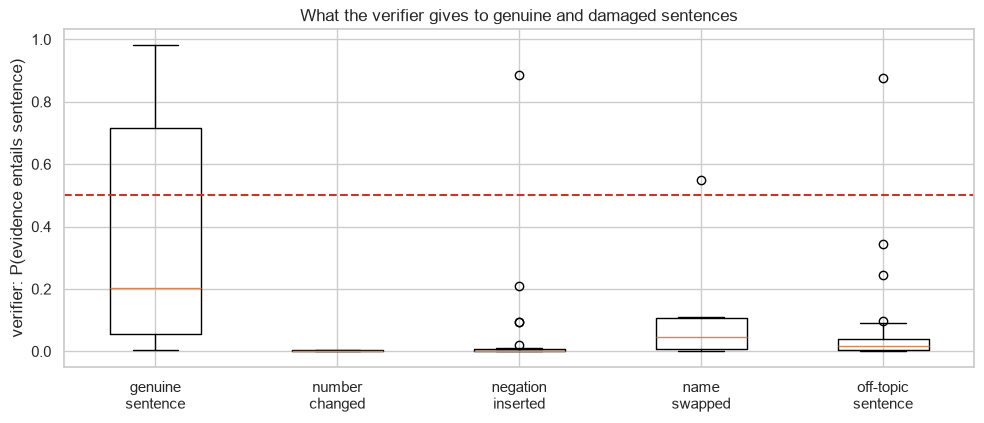

In [4]:
rng = random.Random(1); base = []
for t in TOPICS:
    for q in planner.plan(t)[:3]:
        f = researcher.research(t, q); premise = " ".join(s for s, _ in f["evidence"])
        for s, pids in EXT.write(f)[:1]: base.append((t, s, premise))
print(len(base), "genuine sentences")
other = lambda t: rng.choice([s for tt, s, _ in base if tt != t])
def _chg(m):
    try: return str(int(float(m.group().replace(",", "")) * rng.choice([2, 3, 0.5, 10])) + rng.choice([7, 13, 41]))
    except Exception: return m.group()
def corrupt(kind, t, s):
    if kind == "number changed":
        nums = re.findall(r"\b\d[\d,\.]*\b", s)
        if not nums: return None
        return re.sub(r"\b\d[\d,\.]*\b", _chg, s)
    if kind == "negation inserted":
        m = re.search(r"\b(is|are|was|were|has|have|can|does|do|will)\b", s)
        return s[:m.end()] + " not" + s[m.end():] if m else None
    if kind == "name swapped":
        caps = [w for w in re.findall(r"\b[A-Z][a-z]{3,}\b", s)][1:]
        if not caps: return None
        donor = re.findall(r"\b[A-Z][a-z]{3,}\b", other(t)); donor = [d for d in donor if d not in s]
        return s.replace(rng.choice(caps), rng.choice(donor), 1) if donor else None
    if kind == "off-topic sentence": return other(t)
rows = [("genuine sentence", entail(nli, nli_tok, pr, s), entail(judge, judge_tok, pr, s)) for t, s, pr in base]
for kind in ["number changed", "negation inserted", "name swapped", "off-topic sentence"]:
    for t, s, pr in base:
        c = corrupt(kind, t, s)
        if c and c != s: rows.append((kind, entail(nli, nli_tok, pr, c), entail(judge, judge_tok, pr, c)))
V = pd.DataFrame(rows, columns=["kind", "p_entail", "p_judge"]); V["flagged"] = V.p_entail < 0.5; V["flagged_judge"] = V.p_judge < 0.5
vt = V.groupby("kind").agg(n=("p_entail", "size"), mean_p=("p_entail", "mean"), flagged_pct=("flagged", lambda x: x.mean() * 100), mean_p_judge=("p_judge", "mean"), judge_flagged_pct=("flagged_judge", lambda x: x.mean() * 100)); print(vt.round(2).to_string())
fig, ax = plt.subplots(figsize=(10, 4.4)); order = ["genuine sentence", "number changed", "negation inserted", "name swapped", "off-topic sentence"]
ax.boxplot([V[V.kind == k].p_entail for k in order], tick_labels=[k.replace(" ", "\n", 1) for k in order]); ax.axhline(0.5, color="#c0392b", ls="--"); ax.set_ylabel("verifier: P(evidence entails sentence)"); ax.set_title("What the verifier gives to genuine and damaged sentences"); plt.tight_layout(); plt.show()

**Reading it.** The small verifier (`cross-encoder/nli-MiniLM2-L6-H768`) gives **low scores to damaged sentences**: it flags 97% of inserted negations (30 cases), 97% of off-topic sentences (36), 86% of swapped names (7) and 100% of changed numbers (only 2 cases, too few to say anything). **But it also flags 64% of the genuine sentences** (mean support 0.38): at the usual 0.5 threshold it would reject most of its own correct output. A detector that fires on everything has 'high recall' for free, so the damaged-sentence numbers alone would be misleading. The independent judge (DeBERTa-v3, trained on MNLI, FEVER and ANLI), scored on the same sentences, behaves very differently: **0% of genuine sentences flagged**, 100% of negations, changed numbers and swapped names, and 83% of off-topic sentences. This is the check that makes the judge usable for the next section. (Caveats: the damage is crude and synthetic, the sample is small, and real hallucinations are subtler than inserting 'not'.)

## 5. System-level test: how often does each writer produce unsupported sentences?
12 topics x 5 questions = 60 sections per variant. The **independent judge** (a different, larger NLI model: DeBERTa-v3-base trained on MNLI, FEVER and ANLI) scores each sentence against the evidence the writer was given; **"unsupported" = judge probability of entailment below 0.5**. A cheap, model-free check is added: **new numbers**, i.e. numbers in the sentence that appear nowhere in the evidence. Variants: extractive writer; abstractive writer; abstractive writer with the verifier **guard** (a sentence that fails the verifier is replaced by the extractive top sentence).

In [5]:
t0 = time.time(); variants = {"extractive": (EXT, False), "abstractive": (ABS, False), "abstractive + verifier guard": (ABS, True)}
reports = {}
cache = "../_data/agent_reports.json"
if os.path.exists(cache): reports = json.load(open(cache))
else:
    for name, (w, g) in variants.items():
        reports[name] = {t: build_report(t, w, guard=g, fallback=EXT if g else None) for t in TOPICS}; print(f"{name}: done ({time.time()-t0:.0f}s)")
    json.dump(reports, open(cache, "w"))
nums = lambda s: set(re.findall(r"\d[\d,\.]*\d|\d", s))
rows = []
for name, rep in reports.items():
    for t, secs in rep.items():
        for sec in secs:
            for x in sec["sentences"]:
                pj = entail(judge, judge_tok, sec["premise"], x["text"]); new = nums(x["text"]) - nums(sec["premise"]) - {n.replace(",", "") for n in nums(sec["premise"])}
                rows.append([name, t, pj, pj < 0.5, bool(new), x["p_verifier"], x.get("replaced", False), len(x["text"].split())])
R = pd.DataFrame(rows, columns=["variant", "topic", "p_judge", "unsupported", "new_number", "p_verifier", "replaced", "words"])
T = R.groupby("variant").agg(sentences=("unsupported", "size"), unsupported_pct=("unsupported", lambda x: x.mean() * 100), new_number_pct=("new_number", lambda x: x.mean() * 100), mean_p_judge=("p_judge", "mean"), replaced_pct=("replaced", lambda x: x.mean() * 100), words_per_sentence=("words", "mean")); print(T.round(1).to_string())

                              sentences  unsupported_pct  new_number_pct  mean_p_judge  replaced_pct  words_per_sentence
variant                                                                                                                 
abstractive                         136              0.7             0.0           1.0           0.0                17.9
abstractive + verifier guard        136              1.5             0.0           1.0          56.6                20.2
extractive                          120              2.5             0.0           1.0           0.0                24.6


95% bootstrap intervals of the unsupported share (%): {'extractive': (np.float64(0.0), np.float64(5.8)), 'abstractive': (np.float64(0.0), np.float64(2.2)), 'abstractive + verifier guard': (np.float64(0.0), np.float64(3.7))}


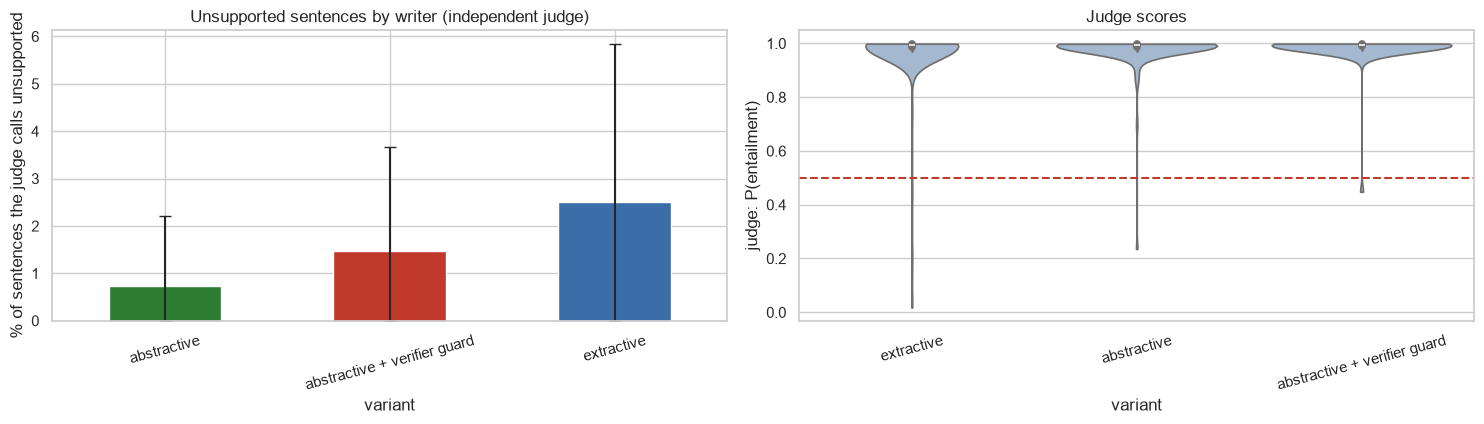

verifier-vs-judge agreement on the abstractive sentences: both say supported 43%, both unsupported 1%, disagree 56%


In [6]:
boot = np.random.RandomState(0); ci = {}
for name in R.variant.unique():
    u = R[R.variant == name].unsupported.to_numpy(float); bs = [u[boot.randint(0, len(u), len(u))].mean() for _ in range(2000)]; ci[name] = (np.percentile(bs, 2.5) * 100, np.percentile(bs, 97.5) * 100)
print("95% bootstrap intervals of the unsupported share (%):", {k: tuple(round(x, 1) for x in v) for k, v in ci.items()})
fig, ax = plt.subplots(1, 2, figsize=(15, 4.4)); T.unsupported_pct.plot.bar(ax=ax[0], yerr=[[T.unsupported_pct[k] - ci[k][0] for k in T.index], [ci[k][1] - T.unsupported_pct[k] for k in T.index]], color=["#2e7d32", "#c0392b", "#3b6ea8"], capsize=4); ax[0].set_ylabel("% of sentences the judge calls unsupported"); ax[0].set_title("Unsupported sentences by writer (independent judge)"); ax[0].tick_params(axis="x", rotation=15)
sns.violinplot(data=R, x="variant", y="p_judge", ax=ax[1], color="#9db8d6", cut=0); ax[1].axhline(0.5, color="#c0392b", ls="--"); ax[1].set_ylabel("judge: P(entailment)"); ax[1].set_title("Judge scores"); ax[1].tick_params(axis="x", rotation=15)
plt.tight_layout(); plt.show()
agree = R[R.variant == "abstractive"]; print("verifier-vs-judge agreement on the abstractive sentences: both say supported %.0f%%, both unsupported %.0f%%, disagree %.0f%%" % (((agree.p_verifier >= .5) & (agree.p_judge >= .5)).mean() * 100, ((agree.p_verifier < .5) & (agree.p_judge < .5)).mean() * 100, ((agree.p_verifier >= .5) != (agree.p_judge >= .5)).mean() * 100))

**Reading it (12 topics x 5 questions; judged by the DeBERTa model against the evidence the writer was given).**
* **Unsupported sentences: abstractive writer 0.7% (1 of 136), abstractive + verifier guard 1.5% (2 of 136), extractive 2.5% (3 of 120).** The intervals are wide (0 to 2.2, 0 to 3.7 and 0 to 5.8%) and overlap completely: **there is no measurable difference** between the three. The extractive rows are copied word for word from the evidence, so any "unsupported" flag on them is the judge's own error: the floor for this judge is therefore a few percent, and all three results sit within it.
* **No sentence of any variant contains a number absent from its evidence** (0% new numbers), and the judge's mean support is 1.0 for all of them. In this set-up the small abstractive writer simply stays close to its source (it is a summariser, which copies heavily), so **there was almost nothing for the guard to fix**.
* **The guard is costly:** it replaced **56.6% of the writer's sentences** with extractive ones, almost all of them false alarms (the verifier and the judge agree that a sentence is supported in 43% of cases and unsupported in 1%, and **disagree in 56%**, where the verifier says unsupported and the judge says supported). A guard whose threshold throws away half of the output while changing the error rate from 0.7% to 1.5% is a bad trade on this evidence.
* What this does *not* show: that LLM-written reports are safe. A larger generative model, or free-form questions, could produce many more unsupported sentences; I did not run one.

## 6. A closer look at unsupported sentences
The abstractive sentences with the lowest judge scores, next to the evidence they were written from (to see *what kind* of error the writer makes).

In [7]:
bad = []
for t, secs in reports["abstractive"].items():
    for sec in secs:
        for x in sec["sentences"]:
            pj = entail(judge, judge_tok, sec["premise"], x["text"]); bad.append((pj, t, sec["question"], x["text"], sec["premise"]))
bad.sort(key=lambda z: z[0])
for pj, t, q, s, prem in bad[:4]: print(f"judge {pj:.3f} | {t}\n  Q: {q}\n  WRITER: {s}\n  EVIDENCE: {prem[:420]}...\n")

judge 0.235 | Coffee
  Q: What are the risks, criticisms or limitations of Coffee?
  WRITER: The statement was based on a scientific review of human research .
  EVIDENCE: Review of clinical trials found that drinking coffee is generally safe within usual levels of intake and is more likely to improve health outcomes than to cause harm at doses of 3–5 cups of coffee daily. The statement was based on a scientific review of human research indicating that regular coffee consumption may be associated with a reduced risk of type 2 diabetes and stroke, although considerable heterogeneity exi...

judge 0.698 | Coffee
  Q: What are the risks, criticisms or limitations of Coffee?
  WRITER: Review of clinical trials found that drinking coffee is generally safe within usual levels of intake and is more likely to improve health outcomes than to cause harm at doses of 3–5 cups of coffee daily .
  EVIDENCE: Review of clinical trials found that drinking coffee is generally safe within usual levels of

**Reading it (the four abstractive sentences with the lowest judge scores).** The errors are not invented facts but **context loss**: "The statement was based on a scientific review of human research" (judge 0.24) uses a phrase that points to something the reader has not been told ("which statement?"); "He claims that the coffee bean originated in the 'land of Sa'ad ad-Din, and the country of Abyssinia, and" is **cut off in the middle of a quotation** (the writer stops at its length limit) and begins with a pronoun without a name; the Climate-change sentence is a verbatim copy of one evidence sentence taken out of its paragraph. A word-for-word-faithful sentence can still mislead when pronouns, quotations and limits lose their antecedents, and a sentence-level support score cannot see that.

## 7. Is the evidence itself good? Retrieval check
For each question, are the retrieved passages really about the question? A rough proxy: the share of the 4 evidence sentences that share at least two content words (not stop words) with the question, and the mean similarity score.

In [8]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS as SW
cw = lambda s: {w for w in re.findall(r"[a-z]{4,}", s.lower()) if w not in SW}
rows = []
for t in TOPICS:
    for q in planner.plan(t):
        f = researcher.research(t, q); rows.append((t, q.split("{t}")[0][:30] if False else q.replace(t, "X"), np.mean(f["scores"]), np.mean([len(cw(q) & cw(s)) >= 2 for s, _ in f["evidence"]])))
RT = pd.DataFrame(rows, columns=["topic", "question_type", "mean_similarity", "share_with_2_shared_words"]); print(RT.groupby("question_type")[["mean_similarity", "share_with_2_shared_words"]].mean().round(2).to_string())

                                                     mean_similarity  share_with_2_shared_words
question_type                                                                                  
How does X work?                                                0.67                       0.40
What are the main uses and applications of X?                   0.60                       0.40
What are the risks, criticisms or limitations of X?             0.60                       0.42
What is X and how is it defined?                                0.67                       0.42
What is the history of X?                                       0.65                       0.48


**Reading it.** The mean similarity between a question and its evidence sentences is 0.60-0.67, and **only 40-48% of the evidence sentences share two or more content words with the question** (about 40% for "how does X work?" and "uses and applications", 48% for "history"). This is a crude proxy (a relevant sentence can use different words), but it matches what the example shows: the first sentences of an article are chosen for almost every question. A better retriever (reading whole sections, re-ranking with a cross-encoder) would matter more than the choice of writer.

## 8. Save: pipeline pieces for the app

In [9]:
P.to_csv("model/wikipedia_passages.csv.gz", index=False, compression="gzip"); np.save("model/passage_embeddings.npy", PE.astype(np.float16))
json.dump({"topics": TOPICS, "verifier": "cross-encoder/nli-MiniLM2-L6-H768", "judge": "MoritzLaurer/DeBERTa-v3-base-mnli-fever-anli", "writer": "sshleifer/distilbart-cnn-6-6", "verifier_planted": vt.round(3).to_dict("index"), "system": T.round(2).to_dict("index"), "ci": {k: [round(x, 2) for x in v] for k, v in ci.items()}}, open("model/meta.json", "w"), indent=1)
json.dump({"abstractive_example": r0}, open("model/example_report.json", "w")); print(os.listdir("model"))

['example_report.json', 'meta.json', 'passage_embeddings.npy', 'wikipedia_passages.csv.gz']


## 9. Where an LLM would plug in (not run here)
```python
import anthropic
class ClaudeAgent:
    def __init__(self, model="claude-haiku-5-5"): self.client = anthropic.Anthropic()          # needs ANTHROPIC_API_KEY
    def ask(self, system, user, max_tokens=400):
        r = self.client.messages.create(model=self.model, max_tokens=max_tokens, system=system, messages=[{"role": "user", "content": user}]); return r.content[0].text
# planner  : ask("Split the topic into 5 sub-questions, one per line.", topic)
# writer   : ask("Write 2 sentences using ONLY the evidence below; cite passage ids like [12].", evidence)
# the Verifier and the independent judge stay exactly as above: they are what makes the LLM's output checkable.
```
I did not run this code (no API key in this session), so nothing about LLM behaviour is claimed in this notebook.

## 10. Summary: my approach vs the reference
| | Reference (Gemini agents) | This notebook |
|---|---|---|
| Agents | Planner, Researcher, Synthesizer (all LLM) | Planner (templates), Researcher (retrieval from 807 Wikipedia passages), Writer (extractive or DistilBART), **Verifier** |
| Evidence | model's own knowledge | cited Wikipedia passages |
| Quality check | read the output | verifier tested on planted errors; independent judge; unsupported-sentence rate with bootstrap interval |
| Findings | a report | verifier catches 86-100% of planted errors **but false-alarms on 64% of genuine sentences**; judge: 0% false alarms, 83-100% detection; unsupported rate 0.7-2.5% for all three writers with overlapping intervals; the guard replaced 56.6% of sentences for no measurable gain |

**What I learned.** (1) Test a checker on **correct** inputs as well as on damaged ones: the verifier looked excellent on errors and was unusable on good text. (2) The checker needs its own checker: I validated the judge on the same planted errors before trusting it. (3) A small summarisation model stays close to its sources, so its unsupported rate is already low; the guard's cost (half of the sentences rewritten) outweighs its benefit here. (4) Faithful sentences can still lose context (pronouns, cut quotations).

**Limits.** No LLM was run (`ClaudeAgent` in section 9 is illustrative); 12 articles and fixed question templates; planted errors are crude and few for numbers (2) and names (7); the judge has its own error floor of a few percent; retrieval returns similar sentences for different questions. **Next steps:** run a real LLM writer with the same verifier and judge, tune the verifier threshold on genuine sentences (or use the DeBERTa model as verifier), and re-rank retrieval with a cross-encoder.